## 원본 bbox 좌표가 이미지 사이즈를 벗어날 수 있을까?

✅ 확인하려는 것: 이미지 사이즈를 벗어나더라도, 오브젝트의 중심과 bbox 중심을 맞춰서 레이블링 된 걸까?

In [22]:
%matplotlib inline

import json
import cv2
import numpy as np
from matplotlib import pyplot as plt

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

In [6]:
anno_file = "/home/dev/data/coco/annotations/person_keypoints_train2017.json"

j = json.load(open(anno_file))
j.keys()

dict_keys(['info', 'licenses', 'images', 'annotations', 'categories'])

In [9]:
images = j['images'][0]
images.keys()

dict_keys(['license', 'file_name', 'coco_url', 'height', 'width', 'date_captured', 'flickr_url', 'id'])

In [8]:
anno = j['annotations'][0]
anno.keys()

dict_keys(['segmentation', 'num_keypoints', 'area', 'iscrowd', 'keypoints', 'image_id', 'bbox', 'category_id', 'id'])

In [28]:
target_anno_id = 1294045

anno id: 1294045
image id: 37015
bbox: [598.66, 256.15, 41.34, 170.23]
(x1,y1): (598.66,256.15), (x2,y2): (640.0, 426.38)

image id: 37015
w(640), h(480)


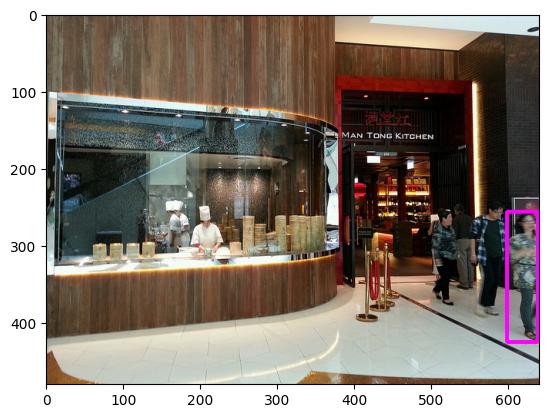

In [29]:
for _anno in j['annotations']:
    if _anno['id'] == target_anno_id:
        print(f"anno id: {_anno['id']}")
        print(f"image id: {_anno['image_id']}")
        target_image_id = _anno['image_id']
        print(f"bbox: {_anno['bbox']}")
        bbox = _anno['bbox']
        x1, y1, w, h = bbox
        x2 = x1 + w
        y2 = y1 + h
        print(f"(x1,y1): ({x1},{y1}), (x2,y2): ({x2}, {y2})")
        break

print('')

for _image in j['images']:
    if _image['id'] == target_image_id:
        print(f"image id: {_image['id']}")
        print(f"w({_image['width']}), h({_image['height']})")
        break

fpath = f"/home/dev/data/coco/images/train2017/{str(int(target_image_id)).zfill(12)}.jpg"

img = cv2.cvtColor(cv2.imread(fpath), cv2.COLOR_BGR2RGB)
img_rec = cv2.rectangle(img, np.array(bbox, dtype=np.int32), COLOR_MAGENTA, 3)

plt.imshow(img_rec)
plt.show()